In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Modèles Scikit-Learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Métriques d'évaluation
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

# Définition du chemin
OUT = Path('resultats')

# Chargement des données d'entraînement et de test
X_train = pd.read_csv(OUT / 'X_train_scaled.csv')
X_test = pd.read_csv(OUT / 'X_test_scaled.csv')

# Chargement des cibles (.squeeze() transforme le DataFrame 1 colonne en une Série Pandas)
y_train = pd.read_csv(OUT / 'y_train.csv').squeeze()
y_test = pd.read_csv(OUT / 'y_test.csv').squeeze()

print(f"Données d'entraînement : {X_train.shape[0]} observations")
print(f"Données de test : {X_test.shape[0]} observations")

Données d'entraînement : 11783 observations
Données de test : 11005 observations


In [3]:
print("Entraînement du modèle Random Forest en cours...")

# Initialisation du modèle avec class_weight='balanced' au cas où les classes 0 et 1 ne seraient pas parfaitement égales
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Apprentissage sur les données d'entraînement
rf_model.fit(X_train, y_train)

print("✅ Modèle Random Forest entraîné avec succès !")

Entraînement du modèle Random Forest en cours...
✅ Modèle Random Forest entraîné avec succès !


--- RAPPORT DE CLASSIFICATION (RANDOM FOREST) ---

                precision    recall  f1-score   support

Pas de Feu (0)       0.68      0.68      0.68      7127
       Feu (1)       0.42      0.42      0.42      3878

      accuracy                           0.59     11005
     macro avg       0.55      0.55      0.55     11005
  weighted avg       0.59      0.59      0.59     11005



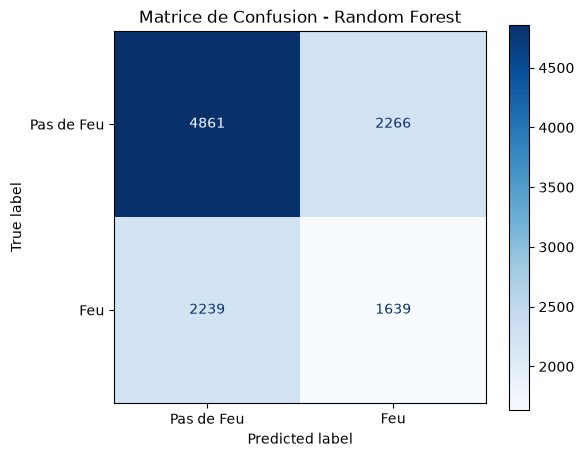

In [4]:
# Prédiction sur le jeu de test
y_pred_rf = rf_model.predict(X_test)

# 1. Rapport de classification (Précision, Rappel, F1-Score)
print("--- RAPPORT DE CLASSIFICATION (RANDOM FOREST) ---\n")
print(classification_report(y_test, y_pred_rf, target_names=['Pas de Feu (0)', 'Feu (1)']))

# 2. Affichage de la Matrice de Confusion
cm = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Pas de Feu', 'Feu'])

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax)
plt.title('Matrice de Confusion - Random Forest')
plt.show()

In [6]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from sklearn.metrics import classification_report

print("Entraînement du modèle SVM en cours (cela peut prendre quelques secondes)...")

# 1. Initialisation du modèle SVM de base (SANS probability=True)
base_svm = SVC(kernel='rbf', random_state=42, class_weight='balanced')

# 2. Ajout de la calibration pour pouvoir calculer les probabilités (recommandation Scikit-Learn)
svm_model = CalibratedClassifierCV(base_svm, ensemble=False)

# 3. Entraînement
svm_model.fit(X_train, y_train)

# 4. Prédiction et évaluation
y_pred_svm = svm_model.predict(X_test)

print("\n--- RAPPORT DE CLASSIFICATION (SVM) ---\n")
print(classification_report(y_test, y_pred_svm, target_names=['Pas de Feu (0)', 'Feu (1)']))

Entraînement du modèle SVM en cours (cela peut prendre quelques secondes)...

--- RAPPORT DE CLASSIFICATION (SVM) ---

                precision    recall  f1-score   support

Pas de Feu (0)       0.65      0.99      0.78      7127
       Feu (1)       0.49      0.03      0.05      3878

      accuracy                           0.65     11005
     macro avg       0.57      0.51      0.42     11005
  weighted avg       0.59      0.65      0.52     11005



Calcul de l'importance des variables en cours...


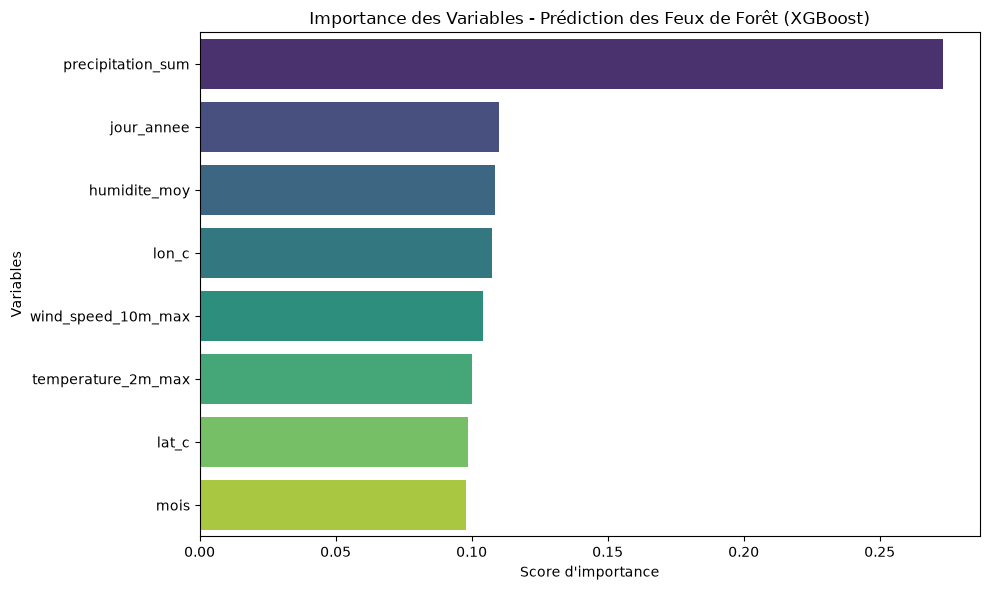

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier

print("Calcul de l'importance des variables en cours...")

# 1. On récupère les noms des variables directement depuis X_train
features = X_train.columns.tolist()

# 2. Entraînement du modèle XGBoost
ratio_desequilibre = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(
    scale_pos_weight=ratio_desequilibre,
    random_state=42,
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6
)
xgb_model.fit(X_train, y_train)

# 3. Récupération de l'importance calculée
feature_importances = xgb_model.feature_importances_

# 4. Création d'un DataFrame pour l'affichage
importance_df = pd.DataFrame({
    'Variable': features,
    'Importance': feature_importances
})

# Tri par ordre d'importance décroissant
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# 5. Génération du graphique
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Variable', data=importance_df, hue='Variable', palette='viridis', legend=False)
plt.title("Importance des Variables - Prédiction des Feux de Forêt (XGBoost)")
plt.xlabel("Score d'importance")
plt.ylabel("Variables")
plt.tight_layout()
plt.show()

Recherche des meilleurs paramètres en cours (GridSearch)... Patientez, cela peut prendre 1 à 2 minutes...
Fitting 3 folds for each of 27 candidates, totalling 81 fits

✅ Recherche terminée !
Meilleurs paramètres trouvés : {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}

--- RAPPORT DE CLASSIFICATION FINAL (XGBOOST OPTIMISÉ) ---

                precision    recall  f1-score   support

Pas de Feu (0)       0.73      0.45      0.56      7127
       Feu (1)       0.41      0.69      0.51      3878

      accuracy                           0.54     11005
     macro avg       0.57      0.57      0.53     11005
  weighted avg       0.62      0.54      0.54     11005



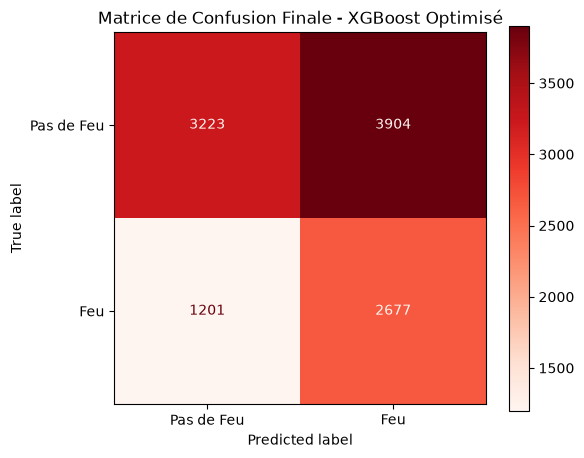

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Recherche des meilleurs paramètres en cours (GridSearch)... Patientez, cela peut prendre 1 à 2 minutes...")

# 1. Définition de la grille des paramètres à tester
param_grid = {
    'max_depth': [4, 6, 8],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 200, 300]
}

# 2. Lancement de la recherche automatique (GridSearchCV)
grid_search = GridSearchCV(
    estimator=XGBClassifier(scale_pos_weight=ratio_desequilibre, random_state=42),
    param_grid=param_grid,
    cv=3,             # Validation croisée en 3 parties
    scoring='f1',     # On cherche le meilleur équilibre Précision / Recall
    n_jobs=-1,        # Utilise tous les cœurs de votre processeur pour aller plus vite
    verbose=1
)
grid_search.fit(X_train, y_train)

# 3. Récupération du meilleur modèle
best_xgb_model = grid_search.best_estimator_

print("\n✅ Recherche terminée !")
print(f"Meilleurs paramètres trouvés : {grid_search.best_params_}")

# 4. Évaluation finale sur les données de test
y_pred_best = best_xgb_model.predict(X_test)

print("\n--- RAPPORT DE CLASSIFICATION FINAL (XGBOOST OPTIMISÉ) ---\n")
print(classification_report(y_test, y_pred_best, target_names=['Pas de Feu (0)', 'Feu (1)']))

# 5. Affichage de la Matrice de Confusion finale
cm_final = confusion_matrix(y_test, y_pred_best)
disp_final = ConfusionMatrixDisplay(confusion_matrix=cm_final, display_labels=['Pas de Feu', 'Feu'])

fig, ax = plt.subplots(figsize=(6, 5))
disp_final.plot(cmap='Reds', ax=ax)
plt.title('Matrice de Confusion Finale - XGBoost Optimisé')
plt.show()

In [18]:
import joblib
from sklearn.preprocessing import StandardScaler

# 1. On recrée et ré-ajuste le scaler sur X_train pour qu'il soit opérationnel
scaler = StandardScaler()
scaler.fit(X_train)

# 2. Sauvegarde du modèle optimisé et du scaler dans le dossier 'resultats'
joblib.dump(best_xgb_model, OUT / 'modele_xgb_optimise.pkl')
joblib.dump(scaler, OUT / 'scaler.pkl')

print("✅ Modèle et scaler sauvegardés avec succès dans le dossier 'resultats' !")

✅ Modèle et scaler sauvegardés avec succès dans le dossier 'resultats' !
